# Исследование объявлений о продаже квартир

В вашем распоряжении данные сервиса Яндекс.Недвижимость — архив объявлений о продаже квартир в Санкт-Петербурге и соседних населённых пунктов за несколько лет. Нужно научиться определять рыночную стоимость объектов недвижимости. Ваша задача — установить параметры. Это позволит построить автоматизированную систему: она отследит аномалии и мошенническую деятельность. 

По каждой квартире на продажу доступны два вида данных. Первые вписаны пользователем, вторые — получены автоматически на основе картографических данных. Например, расстояние до центра, аэропорта, ближайшего парка и водоёма. 

### Откройте файл с данными и изучите общую информацию. 

**Загрузим библиотеки. Откроем файл с данными**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
import pprint
import numpy as np


In [2]:
pd.set_option('display.max_columns', None)
pd.options.display.float_format = '{:,.2f}'.format

**Изучим информацию о данных**

In [3]:
df = pd.read_csv('/datasets/real_estate_data.csv', sep='\t') 
df.head(10)

,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,studio,open_plan,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
0,20,"13,000,000.00",108.00,2019-03-07T00:00:00,3,2.70,16.00,51.00,8,NaN,False,False,25.00,NaN,Санкт-Петербург,"18,863.00","16,028.00",1.00,482.00,2.00,755.00,NaN
1,7,"3,350,000.00",40.40,2018-12-04T00:00:00,1,NaN,11.00,18.60,1,NaN,False,False,11.00,2.00,посёлок Шушары,"12,817.00","18,603.00",0.00,NaN,0.00,NaN,81.00
2,10,"5,196,000.00",56.00,2015-08-20T00:00:00,2,NaN,5.00,34.30,4,NaN,False,False,8.30,0.00,Санкт-Петербург,"21,741.00","13,933.00",1.00,90.00,2.00,574.00,558.00
3,0,"64,900,000.00",159.00,2015-07-24T00:00:00,3,NaN,14.00,NaN,9,NaN,False,False,NaN,0.00,Санкт-Петербург,"28,098.00","6,800.00",2.00,84.00,3.00,234.00,424.00
4,2,"10,000,000.00",100.00,2018-06-19T00:00:00,2,3.03,14.00,32.00,13,NaN,False,False,41.00,NaN,Санкт-Петербург,"31,856.00","8,098.00",2.00,112.00,1.00,48.00,121.00
5,10,"2,890,000.00",30.40,2018-09-10T00:00:00,1,NaN,12.00,14.40,5,NaN,False,False,9.10,NaN,городской посёлок Янино-1,NaN,NaN,NaN,NaN,NaN,NaN,55.00
6,6,"3,700,000.00",37.30,2017-11-02T00:00:00,1,NaN,26.00,10.60,6,NaN,False,False,14.40,1.00,посёлок Парголово,"52,996.00","19,143.00",0.00,NaN,0.00,NaN,155.00
7,5,"7,915,000.00",71.60,2019-04-18T00:00:00,2,NaN,24.00,NaN,22,NaN,False,False,18.90,2.00,Санкт-Петербург,"23,982.00","11,634.00",0.00,NaN,0.00,NaN,NaN
8,20,"2,900,000.00",33.16,2018-05-23T00:00:00,1,NaN,27.00,15.43,26,NaN,False,False,8.81,NaN,посёлок Мурино,NaN,NaN,NaN,NaN,NaN,NaN,189.00
9,18,"5,400,000.00",61.00,2017-02-26T00:00:00,3,2.50,9.00,43.60,7,NaN,False,False,6.50,2.00,Санкт-Петербург,"50,898.00","15,008.00",0.00,NaN,0.00,NaN,289.00


In [4]:
df.tail(10)

,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,studio,open_plan,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
23689,13,"3,550,000.00",35.30,2018-02-28T00:00:00,1,2.86,15.00,16.30,4,NaN,False,False,9.10,2.00,Санкт-Петербург,"17,284.00","16,081.00",1.00,353.00,2.00,652.00,29.00
23690,3,"5,500,000.00",52.00,2018-07-19T00:00:00,2,NaN,5.00,31.00,2,NaN,False,False,6.00,NaN,Санкт-Петербург,"20,151.00","6,263.00",1.00,300.00,0.00,NaN,15.00
23691,11,"9,470,000.00",72.90,2016-10-13T00:00:00,2,2.75,25.00,40.30,7,NaN,False,False,10.60,1.00,Санкт-Петербург,"19,424.00","4,489.00",0.00,NaN,1.00,806.00,519.00
23692,2,"1,350,000.00",30.00,2017-07-07T00:00:00,1,NaN,5.00,17.50,4,NaN,False,False,6.00,NaN,Тихвин,NaN,NaN,NaN,NaN,NaN,NaN,413.00
23693,9,"4,600,000.00",62.40,2016-08-05T00:00:00,3,2.60,9.00,40.00,8,NaN,False,False,8.00,0.00,Петергоф,"45,602.00","34,104.00",1.00,352.00,1.00,675.00,239.00
23694,9,"9,700,000.00",133.81,2017-03-21T00:00:00,3,3.70,5.00,73.30,3,NaN,False,False,13.83,NaN,Санкт-Петербург,"24,665.00","4,232.00",1.00,796.00,3.00,381.00,NaN
23695,14,"3,100,000.00",59.00,2018-01-15T00:00:00,3,NaN,5.00,38.00,4,NaN,False,False,8.50,NaN,Тосно,NaN,NaN,NaN,NaN,NaN,NaN,45.00
23696,18,"2,500,000.00",56.70,2018-02-11T00:00:00,2,NaN,3.00,29.70,1,NaN,False,False,NaN,NaN,село Рождествено,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23697,13,"11,475,000.00",76.75,2017-03-28T00:00:00,2,3.00,17.00,NaN,12,NaN,False,False,23.30,2.00,Санкт-Петербург,"39,140.00","10,364.00",2.00,173.00,3.00,196.00,602.00
23698,4,"1,350,000.00",32.30,2017-07-21T00:00:00,1,2.50,5.00,12.30,1,NaN,False,False,9.00,NaN,поселок Новый Учхоз,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df.sample()

,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,studio,open_plan,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
15618,12,"7,500,000.00",46.90,2019-04-29T00:00:00,1,2.80,25.00,18.80,21,False,False,False,14.50,1.00,Санкт-Петербург,"51,340.00","15,363.00",0.00,NaN,1.00,853.00,NaN


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23699 entries, 0 to 23698
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   total_images          23699 non-null  int64  
 1   last_price            23699 non-null  float64
 2   total_area            23699 non-null  float64
 3   first_day_exposition  23699 non-null  object 
 4   rooms                 23699 non-null  int64  
 5   ceiling_height        14504 non-null  float64
 6   floors_total          23613 non-null  float64
 7   living_area           21796 non-null  float64
 8   floor                 23699 non-null  int64  
 9   is_apartment          2775 non-null   object 
 10  studio                23699 non-null  bool   
 11  open_plan             23699 non-null  bool   
 12  kitchen_area          21421 non-null  float64
 13  balcony               12180 non-null  float64
 14  locality_name         23650 non-null  object 
 15  airports_nearest   

In [7]:
df.isnull().sum().sort_values()

total_images                0
open_plan                   0
floor                       0
rooms                       0
studio                      0
total_area                  0
last_price                  0
first_day_exposition        0
locality_name              49
floors_total               86
living_area              1903
kitchen_area             2278
days_exposition          3181
ponds_around3000         5518
parks_around3000         5518
cityCenters_nearest      5519
airports_nearest         5542
ceiling_height           9195
balcony                 11519
ponds_nearest           14589
parks_nearest           15620
is_apartment            20924
dtype: int64

In [8]:
df.isnull().sum().sort_values()/df.shape[0]*100

total_images            0.00
open_plan               0.00
floor                   0.00
rooms                   0.00
studio                  0.00
total_area              0.00
last_price              0.00
first_day_exposition    0.00
locality_name           0.21
floors_total            0.36
living_area             8.03
kitchen_area            9.61
days_exposition        13.42
ponds_around3000       23.28
parks_around3000       23.28
cityCenters_nearest    23.29
airports_nearest       23.38
ceiling_height         38.80
balcony                48.61
ponds_nearest          61.56
parks_nearest          65.91
is_apartment           88.29
dtype: float64

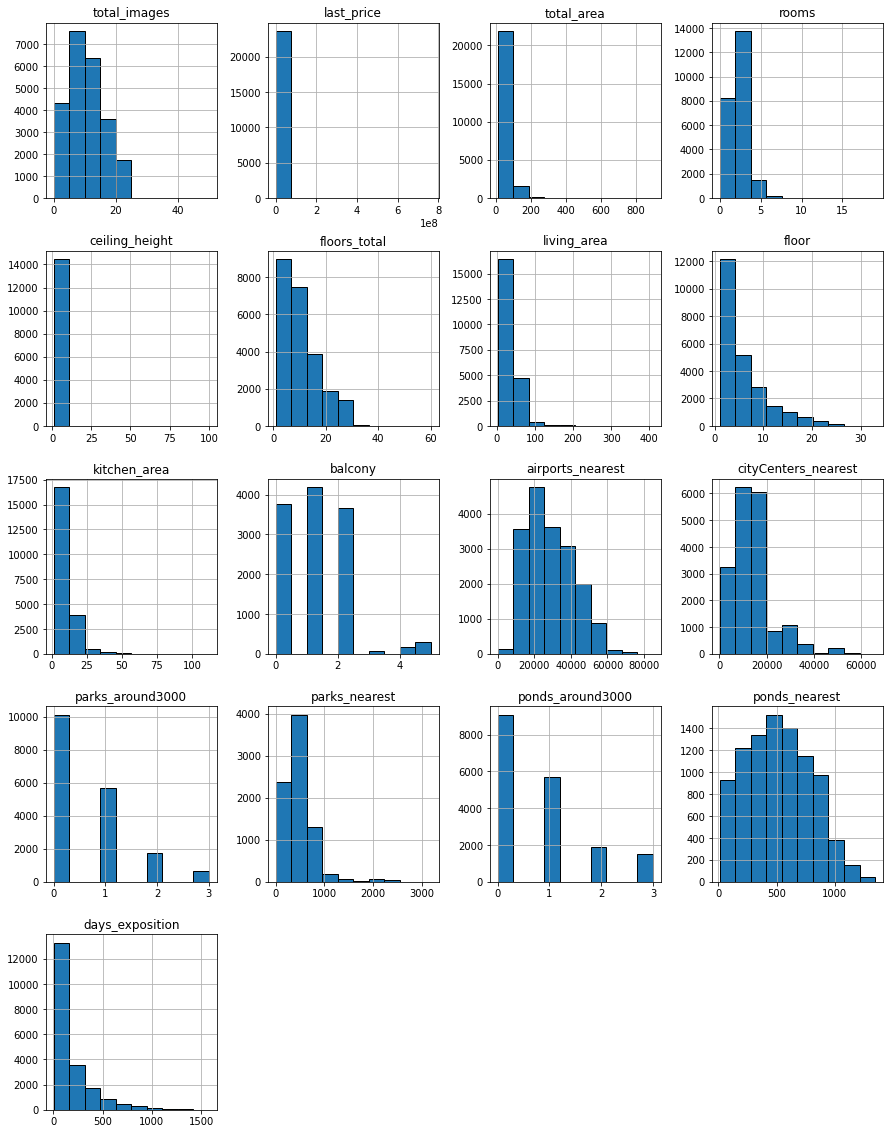

In [9]:
df.hist(figsize=(15, 20), ec='black')
plt.show();

**Пропусков очень много, но большинство выглядит не критично, многие могут не знать расстояние в метрах до центра или до парка, аэропорта. Пропуске в значениях высоты потолков, пользователь может не придать значения или поленится заполнять эти данные. Самое большое количество пропусков в статусах "Апартаменты", большинство пользователей могут не знать, что такое апартаменты на самом деле и не указывают это значение. Так же наблюдаются выбросы по значениям, есть чрезмерно высокие показатели.**

 По типам данных: 
 
1. first_day_exposition - object - должен быть тип datetime
2. ceiling_height - нулевые значения
3. floors_total - должен быть тип int, т.к. количество этажей - целое значение + нулевые значения
4. is_apartment - должен быть тип bool + нулевые значения
5. living_area - нулевые значения
6. kitchen_area - нулевые значения
7. balcony - нулевые значения
8. locality_name  - нулевые значения
9. airports_nearest - нулевые значения
10. cityCenters_nearest - нулевые значения
11. parks_around3000 - тип должен быть int + нулевые значения
12. parks_nearest  - нулевые значения
13. ponds_around3000 - тип должен быть int + нулевые значения
14. ponds_nearest - нулевые значения
15. days_exposition - тип должен быть int + нулевые значения

### Предобработка данных

**Разберёмся с пропусками и изменим типы данных**

In [10]:
pd.DataFrame(round(df.isna().mean()*100,)).style.background_gradient('coolwarm')

,0
total_images,0.000000
last_price,0.000000
total_area,0.000000
first_day_exposition,0.000000
rooms,0.000000
ceiling_height,39.000000
floors_total,0.000000
living_area,8.000000
floor,0.000000
is_apartment,88.000000


In [11]:
#заменим пропуски в days_exposition и заменим тип данных
df['days_exposition'] = df['days_exposition'].fillna(0).astype('int')

In [12]:
#Изучим список населённых пунктов
len(df['locality_name'].unique())

365

In [13]:
df['locality_name'].unique().tolist()

['Санкт-Петербург',
 'посёлок Шушары',
 'городской посёлок Янино-1',
 'посёлок Парголово',
 'посёлок Мурино',
 'Ломоносов',
 'Сертолово',
 'Петергоф',
 'Пушкин',
 'деревня Кудрово',
 'Коммунар',
 'Колпино',
 'поселок городского типа Красный Бор',
 'Гатчина',
 'поселок Мурино',
 'деревня Фёдоровское',
 'Выборг',
 'Кронштадт',
 'Кировск',
 'деревня Новое Девяткино',
 'посёлок Металлострой',
 'посёлок городского типа Лебяжье',
 'посёлок городского типа Сиверский',
 'поселок Молодцово',
 'поселок городского типа Кузьмоловский',
 'садовое товарищество Новая Ропша',
 'Павловск',
 'деревня Пикколово',
 'Всеволожск',
 'Волхов',
 'Кингисепп',
 'Приозерск',
 'Сестрорецк',
 'деревня Куттузи',
 'посёлок Аннино',
 'поселок городского типа Ефимовский',
 'посёлок Плодовое',
 'деревня Заклинье',
 'поселок Торковичи',
 'поселок Первомайское',
 'Красное Село',
 'посёлок Понтонный',
 'Сясьстрой',
 'деревня Старая',
 'деревня Лесколово',
 'посёлок Новый Свет',
 'Сланцы',
 'село Путилово',
 'Ивангород',
 '

In [14]:
#Исправим буквы "е" и "ё"
df['locality_name'] = df['locality_name'].str.replace('ё', 'е', regex=True)

In [15]:
len(df['locality_name'].unique())

331

In [16]:
df['locality_name'].isna().sum()

49

In [17]:
# Удалим строки без указания города, такие объявления не нужны.
df = df.dropna(subset=['locality_name'])

In [18]:
#Изменим тип данных даты
df['first_day_exposition'] = pd.to_datetime(df['first_day_exposition'], format = '%Y-%m-%d')

In [19]:
#Заменим пропуски в balcony на 0 и изменим тип данных на int
df['balcony'].value_counts()
df['balcony'] = df['balcony'].fillna(0)
df['balcony'] = df['balcony'].astype('int')

In [20]:
df['balcony'].value_counts().sort_values()

3       81
4      182
5      304
2     3658
1     4187
0    15238
Name: balcony, dtype: int64

In [21]:
#Все Nan значения в столбце апартаменты заменим на False, так как объекты относятся к жилому фонду.
#Или столбец со значением апартаменты добавили как новое дополнение к таблице.
df['is_apartment'] = df['is_apartment'].fillna(False)

In [22]:
df['is_apartment'].value_counts().sort_values()

True        50
False    23600
Name: is_apartment, dtype: int64

In [23]:
#изменим цену на тип int
df['last_price'] = df['last_price'].astype('int')
df['last_price']

0        13000000
1         3350000
2         5196000
3        64900000
4        10000000
           ...   
23694     9700000
23695     3100000
23696     2500000
23697    11475000
23698     1350000
Name: last_price, Length: 23650, dtype: int64

In [24]:
df[['total_images', 'last_price', 'total_area', 'first_day_exposition',
       'rooms', 'ceiling_height', 'floors_total', 'living_area', 'floor',
       'is_apartment', 'studio', 'open_plan', 'kitchen_area', 'balcony',
       'locality_name', 'airports_nearest', 'cityCenters_nearest',
       'parks_around3000', 'parks_nearest', 'ponds_around3000',
       'ponds_nearest', 'days_exposition']].describe()

,total_images,last_price,total_area,rooms,ceiling_height,floors_total,living_area,floor,kitchen_area,balcony,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
count,"23,650.00","23,650.00","23,650.00","23,650.00","14,490.00","23,565.00","21,752.00","23,650.00","21,381.00","23,650.00","18,116.00","18,139.00","18,140.00","8,064.00","18,140.00","9,085.00","23,650.00"
mean,9.86,"6,541,126.90",60.33,2.07,2.77,10.68,34.45,5.89,10.57,0.59,"28,803.23","14,197.86",0.61,490.83,0.77,518.06,156.45
std,5.68,"10,896,399.18",35.66,1.08,1.26,6.59,22.04,4.88,5.90,0.96,"12,637.31","8,606.83",0.80,342.55,0.94,277.84,213.56
min,0.00,"12,190.00",12.00,0.00,1.00,1.00,2.00,1.00,1.30,0.00,0.00,181.00,0.00,1.00,0.00,13.00,0.00
25%,6.00,"3,400,000.00",40.00,1.00,2.52,5.00,18.60,2.00,7.00,0.00,"18,575.75","9,241.00",0.00,288.00,0.00,293.00,22.00
50%,9.00,"4,650,000.00",52.00,2.00,2.65,9.00,30.00,4.00,9.10,0.00,"26,756.50","13,105.00",0.00,454.50,1.00,502.00,73.00
75%,14.00,"6,799,000.00",69.70,3.00,2.80,16.00,42.30,8.00,12.00,1.00,"37,294.00","16,293.00",1.00,612.00,1.00,730.00,198.00
max,50.00,"763,000,000.00",900.00,19.00,100.00,60.00,409.70,33.00,112.00,5.00,"84,869.00","65,968.00",3.00,"3,190.00",3.00,"1,344.00","1,580.00"


In [25]:
#Проверим на явные дубликаты
df.duplicated().sum()

0

### Посчитайте и добавьте в таблицу новые столбцы

**Добавим новые колонки в таблицу, приведём растояния к километрам**

In [26]:
#Посчитаем и добавим цену за квадратный метр
df['price_of_m2'] = df['last_price']/df['total_area']

In [27]:
#Добавим столбцы растояний, приведем растояния к километрам.
df['cityCenters_nearest_km'] = df['cityCenters_nearest'].apply(lambda x: x/1000)
df['airports_nearest_distance_km'] = df['airports_nearest'].apply(lambda x: x/1000)
df['parks_nearest_km'] = df['parks_nearest'].apply(lambda x: x/1000)
df['ponds_nearest_km'] = df['ponds_nearest'].apply(lambda x: x/1000)

In [28]:
df.head()

,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,studio,open_plan,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition,price_of_m2,cityCenters_nearest_km,airports_nearest_distance_km,parks_nearest_km,ponds_nearest_km
0,20,13000000,108.00,2019-03-07,3,2.70,16.00,51.00,8,False,False,False,25.00,0,Санкт-Петербург,"18,863.00","16,028.00",1.00,482.00,2.00,755.00,0,"120,370.37",16.03,18.86,0.48,0.76
1,7,3350000,40.40,2018-12-04,1,NaN,11.00,18.60,1,False,False,False,11.00,2,поселок Шушары,"12,817.00","18,603.00",0.00,NaN,0.00,NaN,81,"82,920.79",18.60,12.82,NaN,NaN
2,10,5196000,56.00,2015-08-20,2,NaN,5.00,34.30,4,False,False,False,8.30,0,Санкт-Петербург,"21,741.00","13,933.00",1.00,90.00,2.00,574.00,558,"92,785.71",13.93,21.74,0.09,0.57
3,0,64900000,159.00,2015-07-24,3,NaN,14.00,NaN,9,False,False,False,NaN,0,Санкт-Петербург,"28,098.00","6,800.00",2.00,84.00,3.00,234.00,424,"408,176.10",6.80,28.10,0.08,0.23
4,2,10000000,100.00,2018-06-19,2,3.03,14.00,32.00,13,False,False,False,41.00,0,Санкт-Петербург,"31,856.00","8,098.00",2.00,112.00,1.00,48.00,121,"100,000.00",8.10,31.86,0.11,0.05


In [29]:
# Добавим столбцы c днем, месяцем и годом
df['year'] = df['first_day_exposition'].apply(lambda x: x.year)
df['month'] = df['first_day_exposition'].apply(lambda x: x.month)
df['day'] = df['first_day_exposition'].apply(lambda x: x.day_name())

In [30]:
df.head()

,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,studio,open_plan,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition,price_of_m2,cityCenters_nearest_km,airports_nearest_distance_km,parks_nearest_km,ponds_nearest_km,year,month,day
0,20,13000000,108.00,2019-03-07,3,2.70,16.00,51.00,8,False,False,False,25.00,0,Санкт-Петербург,"18,863.00","16,028.00",1.00,482.00,2.00,755.00,0,"120,370.37",16.03,18.86,0.48,0.76,2019,3,Thursday
1,7,3350000,40.40,2018-12-04,1,NaN,11.00,18.60,1,False,False,False,11.00,2,поселок Шушары,"12,817.00","18,603.00",0.00,NaN,0.00,NaN,81,"82,920.79",18.60,12.82,NaN,NaN,2018,12,Tuesday
2,10,5196000,56.00,2015-08-20,2,NaN,5.00,34.30,4,False,False,False,8.30,0,Санкт-Петербург,"21,741.00","13,933.00",1.00,90.00,2.00,574.00,558,"92,785.71",13.93,21.74,0.09,0.57,2015,8,Thursday
3,0,64900000,159.00,2015-07-24,3,NaN,14.00,NaN,9,False,False,False,NaN,0,Санкт-Петербург,"28,098.00","6,800.00",2.00,84.00,3.00,234.00,424,"408,176.10",6.80,28.10,0.08,0.23,2015,7,Friday
4,2,10000000,100.00,2018-06-19,2,3.03,14.00,32.00,13,False,False,False,41.00,0,Санкт-Петербург,"31,856.00","8,098.00",2.00,112.00,1.00,48.00,121,"100,000.00",8.10,31.86,0.11,0.05,2018,6,Tuesday


In [31]:
# Добавим этажи
def floor_status(row):
    if row['floor'] == 1:
        return 'первый'
    elif row['floor'] == row['floors_total']:
        return 'последний'
    else:
        return 'другой'

In [32]:
df['floor_status'] = df.apply(floor_status, axis=1)

In [33]:
#Добавим столбцы с соотношением жилой и общей площади, а также с отношением площади кухни к общей:
df['living_area_part'] = df['living_area']/df['total_area']
df['kitchen_area_part'] = df['kitchen_area']/df['total_area']

In [34]:
df.head()

,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,studio,open_plan,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition,price_of_m2,cityCenters_nearest_km,airports_nearest_distance_km,parks_nearest_km,ponds_nearest_km,year,month,day,floor_status,living_area_part,kitchen_area_part
0,20,13000000,108.00,2019-03-07,3,2.70,16.00,51.00,8,False,False,False,25.00,0,Санкт-Петербург,"18,863.00","16,028.00",1.00,482.00,2.00,755.00,0,"120,370.37",16.03,18.86,0.48,0.76,2019,3,Thursday,другой,0.47,0.23
1,7,3350000,40.40,2018-12-04,1,NaN,11.00,18.60,1,False,False,False,11.00,2,поселок Шушары,"12,817.00","18,603.00",0.00,NaN,0.00,NaN,81,"82,920.79",18.60,12.82,NaN,NaN,2018,12,Tuesday,первый,0.46,0.27
2,10,5196000,56.00,2015-08-20,2,NaN,5.00,34.30,4,False,False,False,8.30,0,Санкт-Петербург,"21,741.00","13,933.00",1.00,90.00,2.00,574.00,558,"92,785.71",13.93,21.74,0.09,0.57,2015,8,Thursday,другой,0.61,0.15
3,0,64900000,159.00,2015-07-24,3,NaN,14.00,NaN,9,False,False,False,NaN,0,Санкт-Петербург,"28,098.00","6,800.00",2.00,84.00,3.00,234.00,424,"408,176.10",6.80,28.10,0.08,0.23,2015,7,Friday,другой,NaN,NaN
4,2,10000000,100.00,2018-06-19,2,3.03,14.00,32.00,13,False,False,False,41.00,0,Санкт-Петербург,"31,856.00","8,098.00",2.00,112.00,1.00,48.00,121,"100,000.00",8.10,31.86,0.11,0.05,2018,6,Tuesday,другой,0.32,0.41


In [35]:
df['cityCenters_nearest_km'].unique()

array([16.028, 18.603, 13.933, ..., 27.977,  7.262,  6.263])

In [36]:
#Округлим значение растояний в километрах
df['cityCenters_nearest_km'] = df[df['cityCenters_nearest_km'].notnull()]['cityCenters_nearest_km'].round()

In [37]:
df['cityCenters_nearest_km'].unique()

array([16., 19., 14.,  7.,  8., nan, 12., 15., 52., 33., 31., 11., 13.,
       10.,  2., 32.,  4., 17., 30.,  5., 51., 50., 24., 18.,  9., 28.,
        3.,  6., 27., 21., 49., 35., 36., 34.,  1., 29., 26., 53., 22.,
       55., 20., 23., 25.,  0., 66., 47., 40., 57., 37., 41., 43., 48.,
       62., 60., 39., 42., 65., 54., 59., 45., 61., 63.])

### Проведите исследовательский анализ данных

In [38]:
#Изучим значения.
df[['total_area', 'living_area', 'kitchen_area', 'last_price', 'rooms', 'ceiling_height', 'floor', 'floor_status', 'floors_total', 'cityCenters_nearest', 'airports_nearest', 'parks_nearest', 'day', 'month']].describe()

,total_area,living_area,kitchen_area,last_price,rooms,ceiling_height,floor,floors_total,cityCenters_nearest,airports_nearest,parks_nearest,month
count,"23,650.00","21,752.00","21,381.00","23,650.00","23,650.00","14,490.00","23,650.00","23,565.00","18,139.00","18,116.00","8,064.00","23,650.00"
mean,60.33,34.45,10.57,"6,541,126.90",2.07,2.77,5.89,10.68,"14,197.86","28,803.23",490.83,6.40
std,35.66,22.04,5.90,"10,896,399.18",1.08,1.26,4.88,6.59,"8,606.83","12,637.31",342.55,3.49
min,12.00,2.00,1.30,"12,190.00",0.00,1.00,1.00,1.00,181.00,0.00,1.00,1.00
25%,40.00,18.60,7.00,"3,400,000.00",1.00,2.52,2.00,5.00,"9,241.00","18,575.75",288.00,3.00
50%,52.00,30.00,9.10,"4,650,000.00",2.00,2.65,4.00,9.00,"13,105.00","26,756.50",454.50,6.00
75%,69.70,42.30,12.00,"6,799,000.00",3.00,2.80,8.00,16.00,"16,293.00","37,294.00",612.00,10.00
max,900.00,409.70,112.00,"763,000,000.00",19.00,100.00,33.00,60.00,"65,968.00","84,869.00","3,190.00",12.00


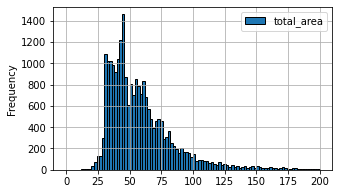

In [39]:
#Нарисуем гистограммы
df.plot(y = 'total_area', kind = 'hist', bins = 100, grid=True, figsize = (5,3), range = (0,200), ec='black')
plt.show();

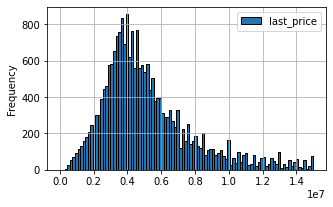

In [40]:
df.plot(y = 'last_price', kind = 'hist', bins = 100, grid=True, range = (0,15000000), figsize = (5,3), ec='black')
plt.show();

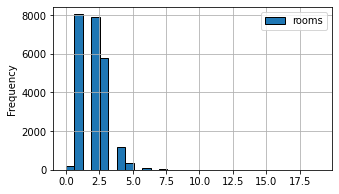

In [41]:
df.plot(y = 'rooms', kind = 'hist', bins = 30, grid=True, figsize = (5,3), ec='black')
plt.show();

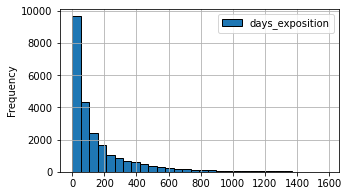

In [42]:
df.plot(y = 'days_exposition', kind = 'hist', bins = 30, grid=True, figsize = (5,3), ec='black')
plt.show();

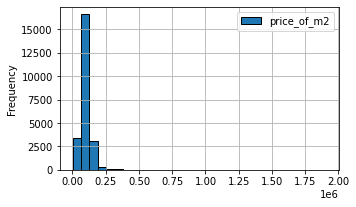

In [43]:
df.plot(y = 'price_of_m2', kind = 'hist', bins = 30, grid=True, figsize = (5,3), ec='black')
plt.show();

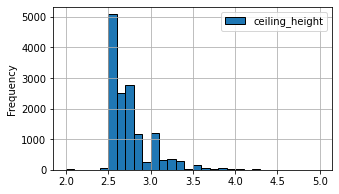

In [44]:
df.plot(y = 'ceiling_height', kind = 'hist', bins = 30, range = (2,5), grid=True, figsize = (5,3), ec='black')
plt.show();

(1.0, 1000.0)

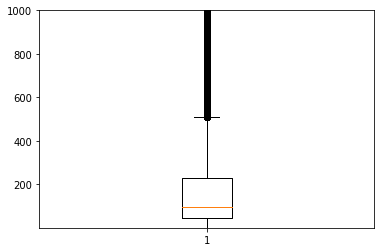

In [45]:
#Изучим, как быстро продавались квартиры (столбец days_exposition)
#Построим диаграмму размаха
plt.boxplot(df[df['days_exposition']!=0]['days_exposition'])
plt.ylim(1,1000)

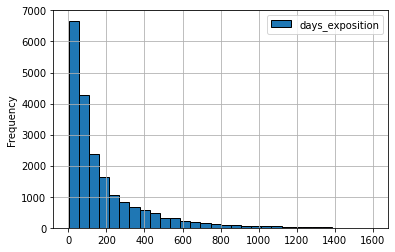

In [46]:
#Построим гистограммы
df.plot(y = 'days_exposition', kind = 'hist', bins = 30, grid = True, range = (1,1600), ec='black')
plt.show();

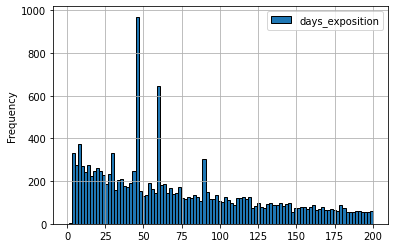

In [47]:
df.plot(y = 'days_exposition', kind = 'hist', bins = 100, grid = True, range = (1,200), ec='black')
plt.show();

In [48]:
#среднее значение, медиана и межквартильный размах
df[df['days_exposition']!=0]['days_exposition'].describe()

count   20,470.00
mean       180.75
std        219.78
min          1.00
25%         45.00
50%         95.00
75%        231.00
max      1,580.00
Name: days_exposition, dtype: float64

 Среднее значение - 180 дней, а медиана - 95 дней. Сделав гистограмму со значениями от 0 до 200 с кол-вом корзин 100, обнаружили выбивающиеся значения и методом value_counts убедились в этом - у нас аномалии на 45, 60, 7, 30, 90 днях - это наиболее популярное количество дней до снятия объявления. Необоснованно долгие объявления свыше 500 дней. Уберём объявления по времени публикации 0, 7, 30, 45, 60, 90 дней. 

count   18,408.00
mean       195.68
std        226.83
min          1.00
25%         44.00
50%        114.00
75%        258.25
max      1,580.00
Name: days_exposition, dtype: float64

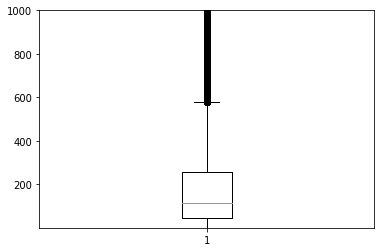

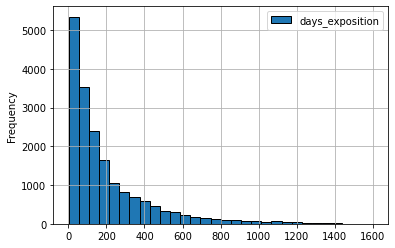

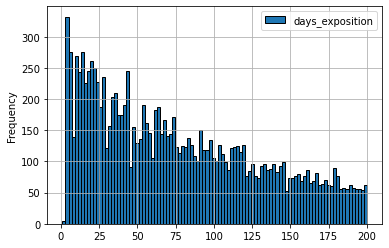

In [49]:
#отфильтруем данные от аномалий и запишем их в новый датафрейм good_df
good_df = df.query('days_exposition != 45 and days_exposition != 30 and days_exposition != 60 and days_exposition != 90 and days_exposition != 7 and days_exposition != 0')

#диаграмма размаха
plt.boxplot(good_df['days_exposition'])
plt.ylim(1,1000)

#гистограммы
good_df.plot(y = 'days_exposition', kind = 'hist', bins = 30, grid = True, range = (1,1600), ec='black')
good_df.plot(y = 'days_exposition', kind = 'hist', bins = 100, grid = True, range = (1,200), ec='black')

#среднее значение, медиана и межквартильный размах
good_df['days_exposition'].describe()

**В очищенных данных получили значения медианы 114 и среднего значения 195, вместо 95 и 180. Нормальные значения располагаются от 1 до 600 дней публикации.**

0.3022017010819025

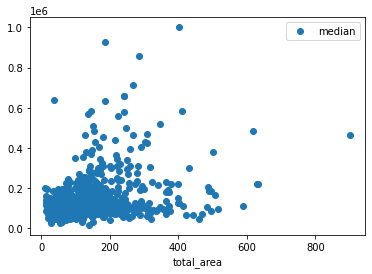

In [50]:
#Изучим зависимость цены квадратного метра от общей площади квартиры.
pivot_table_total_area = df.pivot_table(index = 'total_area', values = 'price_of_m2', aggfunc = ['mean', 'count', 'median'])
pivot_table_total_area.columns = ['mean', 'count', 'median']
pivot_table_total_area.plot(y = 'median', style = 'o')

pivot_table_total_area.sort_values('median', ascending = False)

df['total_area'].corr(df['price_of_m2'])

 **Зависимость слабая - согласно корреляции Пирсона - 0.3. 
 То есть, чем больше площадь тем выше стоимость.**


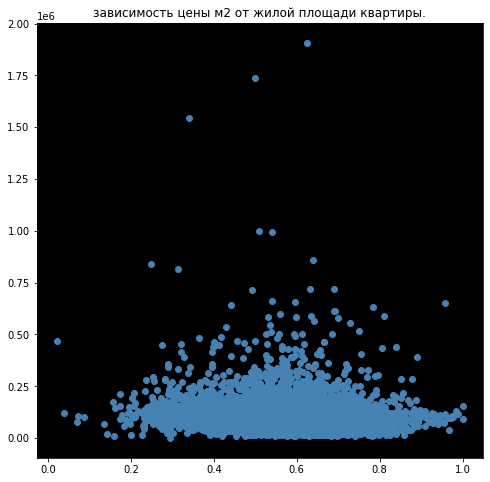

Корреляция составляет: -0.14963049365483477


In [51]:
#Изучим зависимость цены квадратного метра от жилой площади квартиры.
x =  df['living_area_part']   #  x - координаты точек
y =  df['price_of_m2']   #  y - координаты точек

fig, ax = plt.subplots()

ax.scatter(x, y,
           c = 'SteelBlue')    #  цвет точек

ax.set_facecolor('black')     #  цвет области Axes
ax.set_title('зависимость цены м2 от жилой площади квартиры.')     #  заголовок для Axes

fig.set_figwidth(8)     #  ширина и
fig.set_figheight(8)    #  высота "Figure"

plt.show()

print('Корреляция составляет:', df['price_of_m2'].corr(df['living_area_part']))

**Корреляция отрицательная, с большим числом жилой площади квартиры стоят примерно так же как и с меньшим, вероятно зависит от числа комнат, как выяснилось самые дорогие квартиры трёхкомнатные, видимо с большими жилыми площадями неохотно берут квартиры и приходится снижать цены.**

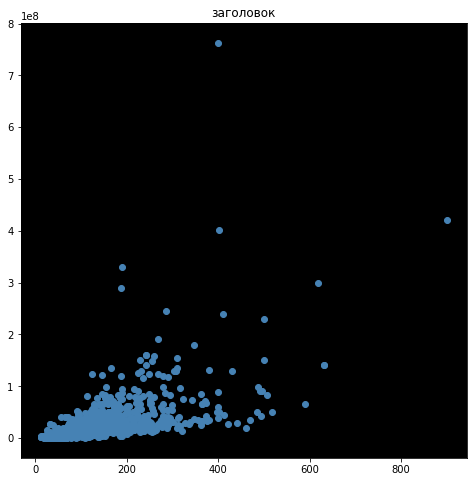

Корреляция составляет: 0.6537428966335393


In [52]:
import numpy as np
import matplotlib.pyplot as plt

x =  df['total_area']   #  x - координаты точек
y =  df['last_price']   #  y - координаты точек

fig, ax = plt.subplots()

ax.scatter(x, y,
           c = 'SteelBlue')    #  цвет точек

ax.set_facecolor('black')     #  цвет области Axes
ax.set_title('заголовок')     #  заголовок для Axes

fig.set_figwidth(8)     #  ширина и
fig.set_figheight(8)    #  высота "Figure"

plt.show()

print('Корреляция составляет:', df['last_price'].corr(df['total_area']))

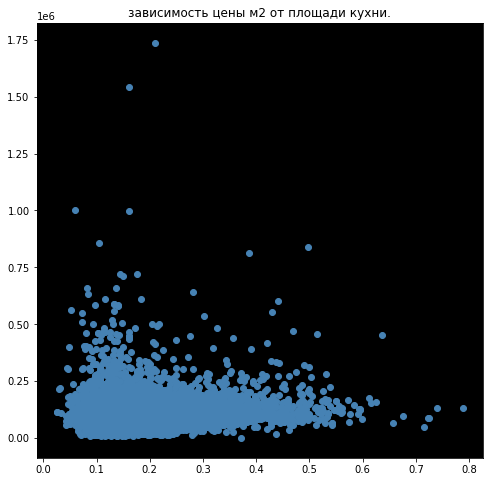

Корреляция составляет: 0.1587432513157257


In [53]:
#Изучим зависимость цены квадратного метра от площади кухни.

x =  df['kitchen_area_part']   #  x - координаты точек
y =  df['price_of_m2']   #  y - координаты точек

fig, ax = plt.subplots()

ax.scatter(x, y,
           c = 'SteelBlue')    #  цвет точек

ax.set_facecolor('black')     #  цвет области Axes
ax.set_title('зависимость цены м2 от площади кухни.')     #  заголовок для Axes

fig.set_figwidth(8)     #  ширина и
fig.set_figheight(8)    #  высота "Figure"

plt.show()

print('Корреляция составляет:', df['kitchen_area_part'].corr(df['price_of_m2']))

 
**С меньшей площадью кухни цены выше, вероятно зависит от количества предложений в процентном соотношении, т.е. с большими кухнями предложений не так много и цены на них в пределах нормы.**

0.05547052981465639

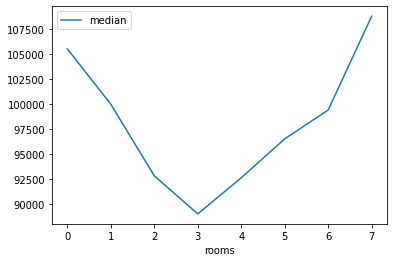

In [54]:
#Изучим зависимость цены квадратного метра от числа комнат.
pivot_table_rooms = df.pivot_table(index = 'rooms', values = 'price_of_m2', aggfunc = ['mean', 'count', 'median'])
pivot_table_rooms.columns = ['mean', 'count', 'median']
pivot_table_rooms.query('count > 50').plot(y = 'median')

pivot_table_rooms.query('count > 50').sort_values('median', ascending = False)

df['rooms'].corr(df['price_of_m2'])

**У трёхкомнатных квартир стоимость квадратного метра самая низкая.**

,mean,count,median
floor_status,,,
другой,"103,508.03",17408,"98,305.44"
первый,"81,989.31",2912,"81,236.81"
последний,"93,378.96",3330,"87,763.15"


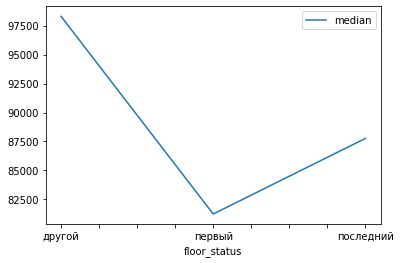

In [55]:
#Изучим зависимость цены квадратного метра от этажа (первого или последнего).
pivot_table_floor_category = df.pivot_table(index = 'floor_status', values = 'price_of_m2', aggfunc = ['mean', 'count', 'median'])
pivot_table_floor_category.columns = ['mean', 'count', 'median']
pivot_table_floor_category.plot(y = 'median')
pivot_table_floor_category

 **Согласно медиане квартиры на первом этаже дешевле квартир на последнем этаже - в среднем на 10%! Странно.**

-0.31809939667400927

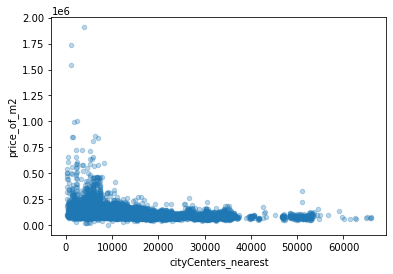

In [56]:
#Изучим зависимость цены квадратного метра от удалённости от центра.
df.plot(kind = 'scatter', y = 'price_of_m2', x = 'cityCenters_nearest', alpha = 0.3)

df['cityCenters_nearest'].corr(df['price_of_m2'])

**Логично, чем ближе к центру города, тем выше цена квадратного метра.**

,mean,count,median
day,,,
Tuesday,"99,724.55",4175,"95,634.10"
Wednesday,"99,605.97",3966,"95,473.81"
Thursday,"100,193.16",4286,"95,152.59"
Monday,"99,470.37",3606,"94,703.96"
Friday,"98,987.22",3992,"94,608.15"
Sunday,"97,763.15",1692,"94,594.59"
Saturday,"99,066.26",1933,"93,548.39"


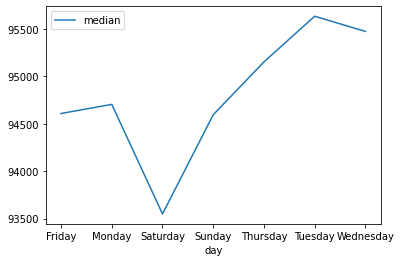

In [57]:
#Изучим зависимость цены квадратного метра от даты размещения: дня недели.
pivot_table_day_exposition = df.pivot_table(index = 'day', values = 'price_of_m2', aggfunc = ['mean', 'count', 'median'])
pivot_table_day_exposition.columns = ['mean', 'count', 'median']
pivot_table_day_exposition.plot(y = 'median')

pivot_table_day_exposition.sort_values('median', ascending = False)

**Самые дешевые квартиры опубликованы в субботу, самые дорогие в четверг.**


,mean,count,median
month,,,
4,"101,956.70",2373,"96,451.61"
8,"100,147.23",1742,"96,103.24"
11,"99,254.44",2367,"95,625.00"
9,"100,490.82",1979,"95,608.78"
3,"98,997.84",2582,"95,293.47"
1,"99,838.43",1491,"95,209.58"
7,"99,650.84",1690,"95,023.94"
2,"98,769.77",2639,"95,000.00"
12,"99,501.62",1638,"94,238.40"


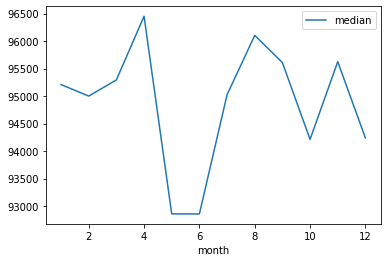

In [58]:
#Изучим зависимость цены квадратного метра от даты размещения: месяц.
pivot_table_month_exposition = df.pivot_table(index = 'month', values = 'price_of_m2', aggfunc = ['mean', 'count', 'median'])
pivot_table_month_exposition.columns = ['mean', 'count', 'median']
pivot_table_month_exposition.plot(y = 'median')

pivot_table_month_exposition.sort_values('median', ascending = False)

**Cамая высокие цены в апреле и августе. Самая низкие цены в мае и июне. В начале лета мы видим наименьшее предложение по количеству и по стоимости недвижимости. Наверное, это связано с летним отпускным сезоном.**


,mean,count,median
year,,,
2014,"124,302.36",136,"106,901.90"
2019,"107,123.78",2879,"103,305.79"
2018,"97,800.07",8512,"95,704.32"
2015,"104,719.10",1173,"93,396.23"
2017,"97,637.36",8185,"92,569.66"
2016,"98,295.37",2765,"91,666.67"


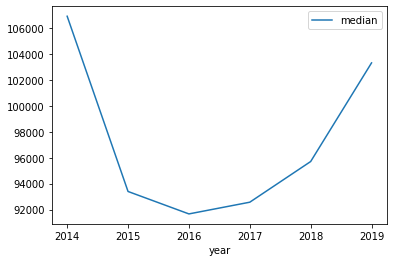

In [59]:
#Изучим зависимость цены квадратного метра от даты размещения: год.
pivot_table_year_exposition = df.pivot_table(index = 'year', values = 'price_of_m2', aggfunc = ['mean', 'count', 'median'])
pivot_table_year_exposition.columns = ['mean', 'count', 'median']
pivot_table_year_exposition.plot(y = 'median')

pivot_table_year_exposition.sort_values('median', ascending = False)

**С 2014 до 2016 года цена падала, но далее начала увеличиваться, в то же время цена была выше при меньшем количестве предложений, по всей видимости сегмент квартир надо рассматривать.**

In [60]:
#Посчитаем среднюю цену одного квадратного метра в 10 населённых пунктах с наибольшим числом объявлений. 
#Определим населённые пункты с самой высокой и низкой стоимостью квадратного метра.
locality_pivot_table = df.pivot_table(index = 'locality_name', values = 'price_of_m2', aggfunc=['count', 'mean'])
locality_pivot_table.columns = ['count', 'mean']
locality_pivot_table = locality_pivot_table.sort_values('count', ascending = False).head(10)
print(locality_pivot_table)
#самая высокая стоимость
locality_pivot_table[locality_pivot_table['mean']==locality_pivot_table['mean'].max()]

                   count       mean
locality_name                      
Санкт-Петербург    15721 114,849.01
поселок Мурино       556  85,681.76
поселок Шушары       440  78,677.36
Всеволожск           398  68,654.47
Пушкин               369 103,125.82
Колпино              338  75,424.58
поселок Парголово    327  90,175.91
Гатчина              307  68,746.15
деревня Кудрово      299  92,473.55
Выборг               237  58,141.91


,count,mean
locality_name,,
Санкт-Петербург,15721,"114,849.01"


In [61]:
#самая низкая стоимость
locality_pivot_table[locality_pivot_table['mean']==locality_pivot_table['mean'].min()]

,count,mean
locality_name,,
Выборг,237,"58,141.91"


,price_of_m2
cityCenters_nearest_km,
0.00,"245,833.53"
1.00,"177,005.41"
2.00,"157,849.01"
3.00,"121,387.45"
4.00,"133,282.87"
5.00,"140,509.79"
6.00,"151,012.19"
7.00,"156,176.88"
8.00,"125,671.44"


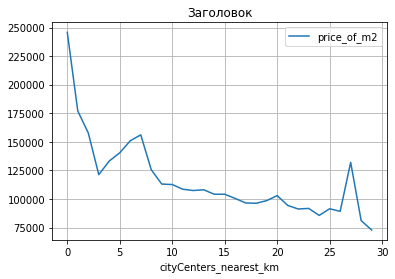

In [63]:
#cityCenters_nearest_km
pivot_table_km = df.query('locality_name == "Санкт-Петербург" and cityCenters_nearest_km !=999999').pivot_table(index = 'cityCenters_nearest_km', values = 'price_of_m2', aggfunc = 'mean')
pivot_table_km.plot(grid = True, title = 'Заголовок')
pivot_table_km

# Cудя по графику центром считается радиус около 5 километров, в этом радиусе самая высокая цена.

### Общий вывод

- Обработали архив данных.
- Обработали пропущенные значения.
- Заменили типы данных на необходимые для удобной работы. 
- Посчитали и добавили в таблицу цену квадратного метра жилья, вывели из даты дни недели, месяцы и года размещения объявлений, добавили категории по этажам квартир. 
- Изучили аномалии в данных параметров. 
- Изучая время продажи квартир.Определили что нормальные значения продажи квартир варьируются от 1 до 600 дней. 
- Определили: Чем больше площадь квартиры, тем выше цена. Цена малозависима от площадей кухни и жилых помещений.Чем больше комнат, тем выше цена, трёхкомнатные квартиры самые дорогие. На первом этаже квартира дешевле, чем на остальных; на последнем дороже, чем на первом, но дешевле чем на остальных.Чем ближе к центру, тем дороже квартира. В самом центре (< 1 км до центра) квартиры стоят на порядок дороже, чем на более удаленных.
- На стоимость квадратного метра влияют день, месяц, год размещения и общая площадь. 
- В 2016-2017 годах стоимость квартир в среднем по рынку была ниже на 10-20 %, тогда как в центре Санкт-Петербурга Квартиры, размещенные к продаже в 2014 году, дороже всех. Период 2015-2018 - период низких цен на квартиры (кризис). 2019г. - рецессия экономики - цены пошли вверх впервые после наступления кризиса.
- Определили центр города в радиусе 7 километров.
- Рассматривая среднюю стоимость квартир в 2014-2019 годах, сегментацию рынка не делали, а лишь смотрели средние показатели по рынку в целом. При изучении растояния до центра Санкт-Петербурга мы увидели ту самую сегментацию.

**Чек-лист готовности проекта**

Поставьте 'x' в выполненных пунктах. Далее нажмите Shift+Enter.

- [x]  открыт файл
- [x]  файлы изучены (выведены первые строки, метод `info()`, гистограммы и т.д.)
- [x]  определены пропущенные значения
- [x]  заполнены пропущенные значения там, где это возможно
- [x]  есть пояснение, какие пропущенные значения обнаружены
- [x]  изменены типы данных
- [x]  есть пояснение, в каких столбцах изменены типы и почему
- [x]  устранены неявные дубликаты в названиях населённых пунктов
- [x]  устранены редкие и выбивающиеся значения (аномалии) во всех столбцах
- [x]  посчитано и добавлено в таблицу: цена одного квадратного метра
- [x]  посчитано и добавлено в таблицу: день публикации объявления (0 - понедельник, 1 - вторник и т.д.)
- [x]  посчитано и добавлено в таблицу: месяц публикации объявления
- [x]  посчитано и добавлено в таблицу: год публикации объявления
- [x]  посчитано и добавлено в таблицу: тип этажа квартиры (значения — «первый», «последний», «другой»)
- [x]  посчитано и добавлено в таблицу: расстояние в км до центра города
- [x]  изучены и описаны следующие параметры:
        - общая площадь;
        - жилая площадь;
        - площадь кухни;
        - цена объекта;
        - количество комнат;
        - высота потолков;
        - этаж квартиры;
        - тип этажа квартиры («первый», «последний», «другой»);
        - общее количество этажей в доме;
        - расстояние до центра города в метрах;
        - расстояние до ближайшего аэропорта;
        - расстояние до ближайшего парка;
        - день и месяц публикации объявления
- [x]  построены гистограммы для каждого параметра
- [x]  выполнено задание: "Изучите, как быстро продавались квартиры (столбец days_exposition). Этот параметр показывает, сколько дней «висело» каждое объявление.
    - Постройте гистограмму.
    - Посчитайте среднее и медиану.
    - В ячейке типа markdown опишите, сколько обычно занимает продажа. Какие продажи можно считать быстрыми, а какие — необычно долгими?"
- [x]  выполнено задание: "Какие факторы больше всего влияют на общую (полную) стоимость объекта? Постройте графики, которые покажут зависимость цены от указанных ниже параметров. Для подготовки данных перед визуализацией вы можете использовать сводные таблицы."
        - общей площади;
        - жилой площади;
        - площади кухни;
        - количество комнат;
        - типа этажа, на котором расположена квартира (первый, последний, другой);
        - даты размещения (день недели, месяц, год);
- [x]  выполнено задание: "Посчитайте среднюю цену одного квадратного метра в 10 населённых пунктах с наибольшим числом объявлений. Выделите населённые пункты с самой высокой и низкой стоимостью квадратного метра. Эти данные можно найти по имени в столбце `locality_name`."
- [x]  выполнено задание: "Ранее вы посчитали расстояние до центра в километрах. Теперь выделите квартиры в Санкт-Петербурге с помощью столбца `locality_name` и вычислите среднюю цену каждого километра. Опишите, как стоимость объектов зависит от расстояния до центра города."
- [x]  в каждом этапе есть промежуточные выводы
- [x]  есть общий вывод